In [2]:
# Import the libraries needed for the project
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import classification_report, confusion_matrix



#Chest X-ray Pneumonia Classification

This project uses deep learning and Convolutional Neural Networks (CNNs)
to classify chest X-ray images into two categories: NORMAL and PNEUMONIA.

In [67]:
import os
from pathlib import Path

BASE_DIR = Path.cwd()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

DATA_DIR = BASE_DIR / "data" / "chest_xray"

TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "val"
TEST_DIR = DATA_DIR / "test"

OUTPUT_DIR = BASE_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
# Check whether the dataset directory exists
print("Dataset folder exists:", DATA_DIR.exists())

# Display the contents of the dataset directory
if DATA_DIR.exists():
    print("\nDataset contents:")
    for item in DATA_DIR.iterdir():
        print(item.name)

Dataset folder exists: True

Dataset contents:
chest_xray


In [3]:
# Define the paths for the training, testing, and validation sets
DATASET_DIR = DATA_DIR / "chest_xray"

TRAIN_DIR = DATASET_DIR / "train"
TEST_DIR = DATASET_DIR / "test"
VAL_DIR = DATASET_DIR / "val"

# Check whether each folder exists
print("Training folder:", TRAIN_DIR.exists())
print("Testing folder:", TEST_DIR.exists())
print("Validation folder:", VAL_DIR.exists())

Training folder: True
Testing folder: True
Validation folder: False


In [4]:
# Define the two image categories
CLASSES = ["NORMAL", "PNEUMONIA"]

# Create a function to count images in each folder
def count_images(folder):
    counts = {}

    for class_name in CLASSES:
        class_folder = folder / class_name

        # Count image files in the category folder
        counts[class_name] = len(list(class_folder.glob("*")))

    return counts

# Count images in each dataset split
train_counts = count_images(TRAIN_DIR)
test_counts = count_images(TEST_DIR)
val_counts = count_images(VAL_DIR)

# Display the results
print("Training images:", train_counts)
print("Testing images:", test_counts)
print("Validation images:", val_counts)

Training images: {'NORMAL': 1341, 'PNEUMONIA': 3377}
Testing images: {'NORMAL': 234, 'PNEUMONIA': 390}
Validation images: {'NORMAL': 0, 'PNEUMONIA': 0}


In [6]:
import pandas as pd

# Combine the image counts into a DataFrame
dataset_summary = pd.DataFrame({
    "Training": train_counts,
    "Testing": test_counts,
    "Validation": val_counts
})

# Display the dataset summary
display(dataset_summary)

# Calculate the total number of images in each category
print("\nTotal NORMAL images:",
      dataset_summary.loc["NORMAL"].sum())

print("Total PNEUMONIA images:",
      dataset_summary.loc["PNEUMONIA"].sum())

,Training,Testing,Validation
NORMAL,1341,234,0
PNEUMONIA,3377,390,0



Total NORMAL images: 1575
Total PNEUMONIA images: 3767


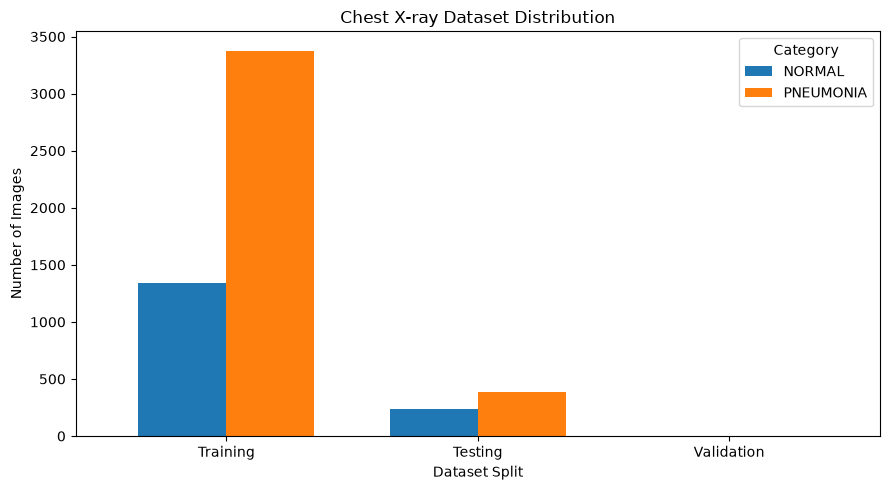

In [8]:
# Create a bar chart showing the number of images in each category
dataset_summary.T.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.7
)

# Add chart labels and title
import matplotlib.pyplot as plt

plt.title("Chest X-ray Dataset Distribution")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.legend(title="Category")
plt.tight_layout()

# Display the chart
plt.show()

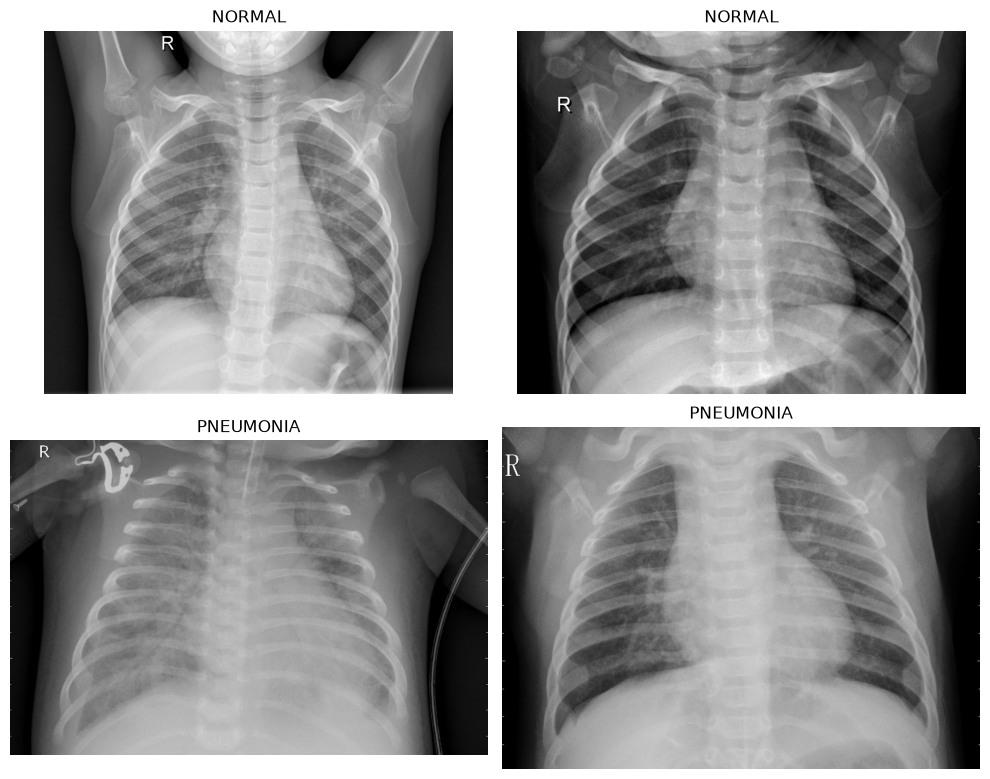

In [62]:
# Create a figure to display sample images

from PIL import Image


plt.figure(figsize=(10, 8))

# Display four sample images from the training dataset
for i, class_name in enumerate(CLASSES):

    # Get image paths from the current category
    image_paths = list((TRAIN_DIR / class_name).glob("*"))[:2]

    for j, image_path in enumerate(image_paths):

        # Open the image
        image = Image.open(image_path).convert("RGB")

        # Add the image to the figure
        plt.subplot(2, 2, i * 2 + j + 1)
        plt.imshow(image)
        plt.title(class_name)
        plt.axis("off")

# Adjust the layout and display the images
plt.tight_layout()
plt.show()

In [12]:
# Collect the dimensions of sample images
image_dimensions = []

# Check a few images from each category
for class_name in CLASSES:
    image_paths = list((TRAIN_DIR / class_name).glob("*"))[:10]

    for image_path in image_paths:
        with Image.open(image_path) as image:
            image_dimensions.append(image.size)

# Display the dimensions
print("Sample image dimensions:")
print(image_dimensions)

Sample image dimensions:
[(2090, 1858), (1422, 1152), (1810, 1434), (1618, 1279), (1600, 1125), (1974, 1306), (1528, 1013), (1384, 1167), (1450, 1144), (1468, 993), (1152, 760), (1072, 768), (1244, 863), (1242, 940), (1488, 1280), (1008, 616), (1184, 816), (856, 480), (1048, 888), (1216, 792)]


In [13]:
# Define the image size used by the CNN
IMAGE_SIZE = (150, 150)

# Define the number of images processed in each batch
BATCH_SIZE = 32

# Define the number of categories
NUM_CLASSES = 2

# Display the preprocessing settings
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Number of classes:", NUM_CLASSES)


Image size: (150, 150)
Batch size: 32
Number of classes: 2


In [59]:
import tensorflow as tf

# Load the training images from their folders
train_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    color_mode="rgb",
    shuffle=True,
    seed=42
)

Found 4718 files belonging to 2 classes.


In [19]:
# Load the validation images
train_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    color_mode="rgb",
    shuffle=True,
    seed=42,
    validation_split=0.2,
    subset="training"
)

Found 4718 files belonging to 2 classes.
Using 3775 files for training.


In [69]:
# Load the training dataset (80%)
train_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    color_mode="rgb",
    shuffle=True
)

# Load the validation dataset (20%)
val_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    color_mode="rgb",
    shuffle=True
)

Found 4718 files belonging to 2 classes.
Using 3775 files for training.
Found 4718 files belonging to 2 classes.
Using 943 files for validation.


In [70]:
# Load the testing images
test_dataset = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    color_mode="rgb",
    shuffle=False
)

# Display the class names
print("Class names:", train_dataset.class_names)

Found 624 files belonging to 2 classes.


Class names: ['NORMAL', 'PNEUMONIA']


In [23]:
# Normalize pixel values for the training dataset
normalization_layer = tf.keras.layers.Rescaling(1./255)

# Apply normalization to all three datasets
train_dataset = train_dataset.map(
    lambda images, labels: (normalization_layer(images), labels)
)

val_dataset = val_dataset.map(
    lambda images, labels: (normalization_layer(images), labels)
)

test_dataset = test_dataset.map(
    lambda images, labels: (normalization_layer(images), labels)
)

In [61]:

# Extract labels from the training dataset
y_train = np.concatenate([
    labels.numpy().reshape(-1)
    for _, labels in train_dataset
]).astype(int)

# Count images in each class
class_counts = np.bincount(y_train, minlength=2)

# Calculate class weights
total_train_images = len(y_train)

class_weights = {
    0: total_train_images / (2 * class_counts[0]),
    1: total_train_images / (2 * class_counts[1])
}

print("Training class counts:", class_counts)
print("Class weights:", class_weights)


Training class counts: [1081 2694]
Class weights: {0: np.float64(1.746068455134135), 1: np.float64(0.7006310319227914)}


## Data Augmentation

Data augmentation increases the variety of training images by applying
small transformations. This helps the CNN generalize better to new images.

In [25]:
# Create data augmentation layers for training images
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.1)
])

# Display the augmentation layers
data_augmentation.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ ?                      │   0 (unbuilt) │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

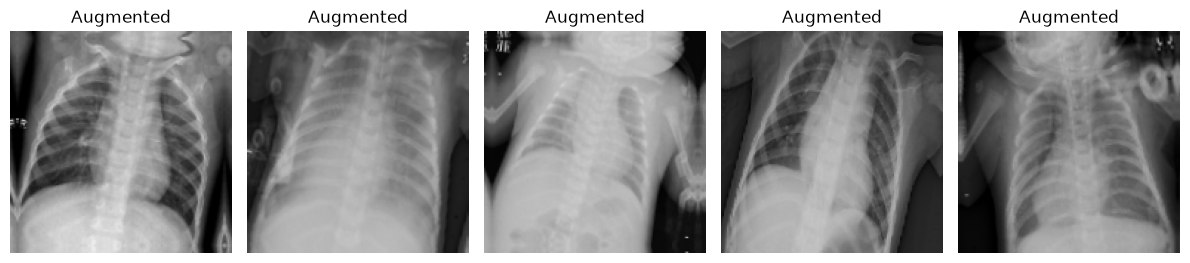

In [26]:
# Get one batch of training images
for images, labels in train_dataset.take(1):
    sample_images = images[:5]
    break

# Create a figure to compare original and augmented images
plt.figure(figsize=(12, 5))

for i in range(5):
    # Apply augmentation to one image
    augmented_image = data_augmentation(
        tf.expand_dims(sample_images[i], axis=0),
        training=True
    )

    # Display the augmented image
    plt.subplot(1, 5, i + 1)
    plt.imshow(augmented_image[0])
    plt.axis("off")
    plt.title("Augmented")

plt.tight_layout()
plt.show()

## CNN Model Architecture

We will build a Convolutional Neural Network with three convolutional
blocks, followed by fully connected layers for binary classification.


In [27]:
# Define the CNN model
model = tf.keras.Sequential([

    # Define the input image shape
    tf.keras.layers.Input(shape=(150, 150, 3)),

    # Apply data augmentation during training
    data_augmentation,

    # First convolutional block
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Second convolutional block
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Third convolutional block
    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Convert feature maps into a one-dimensional vector
    tf.keras.layers.Flatten(),

    # Fully connected layer
    tf.keras.layers.Dense(128, activation="relu"),

    # Dropout to reduce overfitting
    tf.keras.layers.Dropout(0.5),

    # Output layer for binary classification
    tf.keras.layers.Dense(1, activation="sigmoid")
])

# Display the model architecture
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,828,481 (18.42 MB)

 Trainable params: 4,828,481 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

In [28]:
tf.keras.layers.Dense(1, activation="sigmoid")

<Dense name=dense_2, built=False>

In [29]:
# Configure the model for binary classification
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

print("Model compiled successfully!")

Model compiled successfully!


In [30]:
# Calculate the total number of training images
total_train_images = sum(train_counts.values())

# Calculate a weight for each class
class_weights = {
    0: total_train_images / (2 * train_counts["NORMAL"]),
    1: total_train_images / (2 * train_counts["PNEUMONIA"])
}

# Display the calculated class weights
print("Class weights:", class_weights)

Class weights: {0: 1.7591349739000746, 1: 0.6985490079952621}


In [31]:
# Create the directory for saving the best model
MODEL_DIR = BASE_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Define the path where the best model will be saved
best_model_path = MODEL_DIR / "best_chest_xray_model.keras"

# Stop training if validation loss does not improve
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Save the model whenever validation loss improves
model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(best_model_path),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

# Collect all callbacks
callbacks = [early_stopping, model_checkpoint]

print("Training callbacks are ready!")

Training callbacks are ready!


In [32]:
# Define the maximum number of training epochs
EPOCHS = 10

# Train the CNN model
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks
)

Epoch 1/10


c:\Users\zaina\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 328ms/step - accuracy: 0.7452 - loss: 0.4888 - precision: 0.8994 - recall: 0.7238
Epoch 1: val_loss improved from None to 0.41041, saving model to C:\Users\zaina\OneDrive\Desktop\Chest_Xray_Pneumonia_Classification\models\best_chest_xray_model.keras

Epoch 1: finished saving model to C:\Users\zaina\OneDrive\Desktop\Chest_Xray_Pneumonia_Classification\models\best_chest_xray_model.keras
118/118 ━━━━━━━━━━━━━━━━━━━━ 49s 366ms/step - accuracy: 0.7452 - loss: 0.4888 - precision: 0.8994 - recall: 0.7238 - val_accuracy: 0.8091 - val_loss: 0.4104 - val_precision: 0.9961 - val_recall: 0.7394
Epoch 2/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 298ms/step - accuracy: 0.8967 - loss: 0.2588 - precision: 0.9608 - recall: 0.8916
Epoch 2: val_loss improved from 0.41041 to 0.17864, saving model to C:\Users\zaina\OneDrive\Desktop\Chest_Xray_Pneumonia_Classification\models\best_chest_xray_model.keras

Epoch 2: finished saving model to C:\Users\zaina\OneDrive\Desktop\Chest_Xray_Pneu

In [33]:
# Create a DataFrame containing the training history
history_df = pd.DataFrame(history.history)

# Display the training results for each epoch
display(history_df)

# Save the training history as a CSV file
OUTPUT_DIR = BASE_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

history_df.to_csv(
    OUTPUT_DIR / "training_history.csv",
    index=False
)

print("Training history saved successfully!")

,accuracy,loss,precision,recall,val_accuracy,val_loss,val_precision,val_recall
0,0.745166,0.488816,0.899446,0.723831,0.809120,0.410406,0.996055,0.739385
1,0.896689,0.258820,0.960800,0.891611,0.933192,0.178642,0.987421,0.919473
2,0.923974,0.195655,0.971037,0.920935,0.913043,0.237915,0.993432,0.885798
3,0.922914,0.201324,0.971361,0.919079,0.951219,0.135955,0.983308,0.948756
4,0.930331,0.186037,0.974249,0.926875,0.938494,0.184821,0.993681,0.920937
5,0.932450,0.172494,0.975068,0.929102,0.962884,0.121361,0.993902,0.954612
6,0.937483,0.164478,0.976726,0.934670,0.940615,0.161678,0.992151,0.925329
7,0.941987,0.148668,0.979837,0.938010,0.957582,0.123886,0.986384,0.954612
8,0.943046,0.146214,0.978387,0.940980,0.962884,0.117317,0.993902,0.954612
9,0.949934,0.123106,0.981176,0.948033,0.971368,0.109369,0.988095,0.972182


Training history saved successfully!


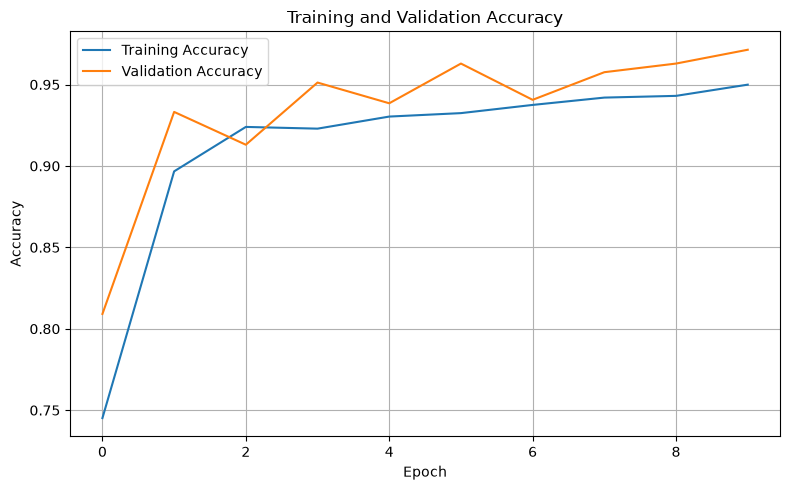

In [34]:
# Plot training and validation accuracy
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()

# Save the accuracy graph
plt.savefig(OUTPUT_DIR / "accuracy_curve.png")

plt.show()

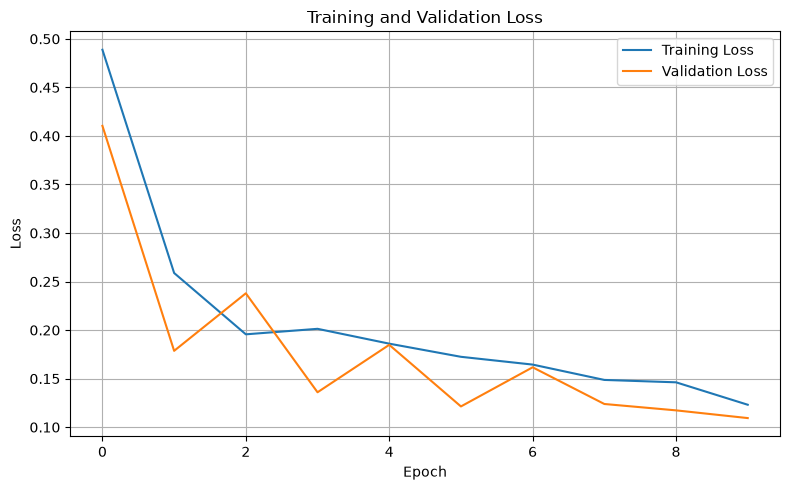

In [35]:
# Plot training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()

# Save the loss graph
plt.savefig(OUTPUT_DIR / "loss_curve.png")

plt.show()

In [36]:
# Load the model with the best validation performance
best_model = tf.keras.models.load_model(best_model_path)

print("Best model loaded successfully!")

Best model loaded successfully!


In [64]:

# Evaluate the best model on the test dataset
test_results = best_model.evaluate(
    test_dataset,
    return_dict=True,
    verbose=1
)

# Display all evaluation metrics
print("\nTest Results:")

for metric_name, metric_value in test_results.items():
    print(f"{metric_name}: {metric_value:.4f}")


20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 97ms/step - accuracy: 0.8429 - loss: 93.9802 - precision: 0.8216 - recall: 0.9564

Test Results:
accuracy: 0.8429
loss: 93.9802
precision: 0.8216
recall: 0.9564


In [39]:
import numpy as np

# Generate prediction probabilities for all test images
y_probabilities = best_model.predict(test_dataset)

# Convert probabilities into binary predictions
y_predictions = (y_probabilities >= 0.5).astype(int).flatten()

# Extract the actual labels from the test dataset
y_true = np.concatenate([
    labels.numpy().reshape(-1)
    for _, labels in test_dataset
]).astype(int)

# Display a few predictions
print("Actual labels:    ", y_true[:10])
print("Predicted labels: ", y_predictions[:10])

20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 89ms/step
Actual labels:     [0 0 0 0 0 0 0 0 0 0]
Predicted labels:  [0 1 1 1 0 1 0 0 1 0]


In [46]:
from sklearn.metrics import classification_report

# Generate a detailed classification report
report = classification_report(
    y_true,
    y_predictions,
    labels=[0, 1],
    target_names=["NORMAL", "PNEUMONIA"],
    digits=4
)

# Display the classification report
print(report)

# Save the report to a text file
with open(OUTPUT_DIR / "classification_report.txt", "w") as file:
    file.write(report)

              precision    recall  f1-score   support

      NORMAL     0.9398    0.5342    0.6812       234
   PNEUMONIA     0.7780    0.9795    0.8672       390

    accuracy                         0.8125       624
   macro avg     0.8589    0.7568    0.7742       624
weighted avg     0.8387    0.8125    0.7974       624



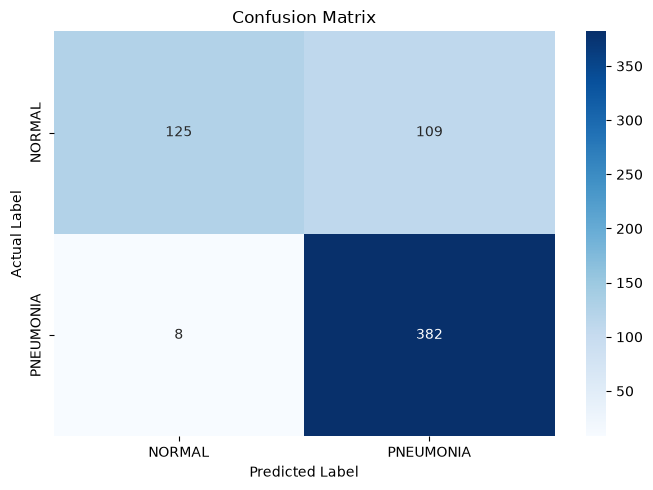

In [63]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Calculate the confusion matrix
cm = confusion_matrix(
    y_true,
    y_predictions,
    labels=[0, 1]
)

# Display the confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["NORMAL", "PNEUMONIA"],
    yticklabels=["NORMAL", "PNEUMONIA"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "confusion_matrix.png")
plt.show()


In [50]:
# Import additional evaluation metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Calculate the evaluation metrics
accuracy = accuracy_score(y_true, y_predictions)
precision = precision_score(y_true, y_predictions)
recall = recall_score(y_true, y_predictions)
f1 = f1_score(y_true, y_predictions)

# Display the results
print("Final Test Metrics")
print("------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

Final Test Metrics
------------------
Accuracy:  0.8125
Precision: 0.7780
Recall:    0.9795
F1-score:  0.8672


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step


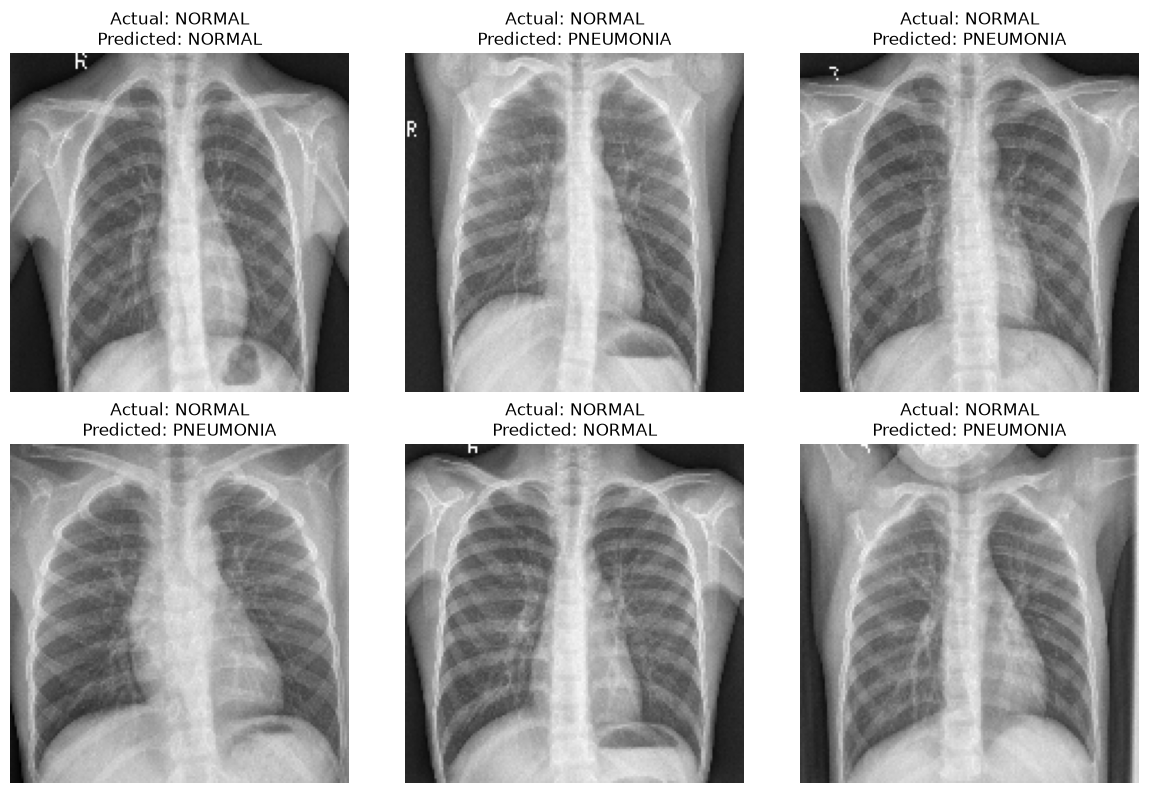

In [51]:
# Get a batch of images and their actual labels
for images, labels in test_dataset.take(1):
    sample_images = images[:6]
    sample_labels = labels[:6].numpy().flatten()

# Generate predictions for the selected images
sample_probabilities = best_model.predict(sample_images)
sample_predictions = (sample_probabilities >= 0.5).astype(int).flatten()

# Define readable class names
class_names = ["NORMAL", "PNEUMONIA"]

# Display the images and their predictions
plt.figure(figsize=(12, 8))

for i in range(6):
    plt.subplot(2, 3, i + 1)

    plt.imshow(sample_images[i].numpy())
    plt.title(
        f"Actual: {class_names[int(sample_labels[i])]}\n"
        f"Predicted: {class_names[sample_predictions[i]]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [71]:
# Create a dictionary containing the main project results
project_summary = {
    "Project": "Chest X-ray Pneumonia Classification",
    "Model": "Convolutional Neural Network (CNN)",
    "Image Size": "150 x 150",
    "Number of Classes": 2,
    "Test Accuracy": accuracy,
    "Test Precision": precision,
    "Test Recall": recall,
    "Test F1-score": f1
}

# Convert the summary into a DataFrame
summary_df = pd.DataFrame(
    list(project_summary.items()),
    columns=["Description", "Value"]
)

# Display the project summary
display(summary_df)

# Save the project summary
summary_df.to_csv(
    OUTPUT_DIR / "project_summary.csv",
    index=False
)

,Description,Value
0,Project,Chest X-ray Pneumonia Classification
1,Model,Convolutional Neural Network (CNN)
2,Image Size,150 x 150
3,Number of Classes,2
4,Test Accuracy,0.8125
5,Test Precision,0.778004
6,Test Recall,0.979487
7,Test F1-score,0.867196
